In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,accuracy_score,classification_report,precision_score,recall_score,f1_score)

In [2]:
df=pd.read_csv('/content/crop.csv')
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
print('shape=',df.shape)
print()
print('dtypes=\n',df.dtypes)
print()
print('first 5 lines=\n',df.head())
print()
print('describe=\n',df.describe())
print()
print('coloumns are=\n',df.columns)


shape= (2200, 8)

dtypes=
 N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

first 5 lines=
     N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice

describe=
                  N            P            K  temperature     humidity  \
count  2200.000000  2200.000000  2200.000000  2200.000000  2200.000000   
mean     50.551818    53.362727    48.149091    25.616244    71.481779   
std      36.917334    32.985883    50.647931     5.063749    22.263812   
min       0.000000     5.000000     5.000000     8.825

In [4]:
df.isna().sum()

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.corr(numeric_only=True)

,N,P,K,temperature,humidity,ph,rainfall
N,1.000000,-0.231460,-0.140512,0.026504,0.190688,0.096683,0.059020
P,-0.231460,1.000000,0.736232,-0.127541,-0.118734,-0.138019,-0.063839
K,-0.140512,0.736232,1.000000,-0.160387,0.190859,-0.169503,-0.053461
temperature,0.026504,-0.127541,-0.160387,1.000000,0.205320,-0.017795,-0.030084
humidity,0.190688,-0.118734,0.190859,0.205320,1.000000,-0.008483,0.094423
ph,0.096683,-0.138019,-0.169503,-0.017795,-0.008483,1.000000,-0.109069
rainfall,0.059020,-0.063839,-0.053461,-0.030084,0.094423,-0.109069,1.000000


<Axes: >

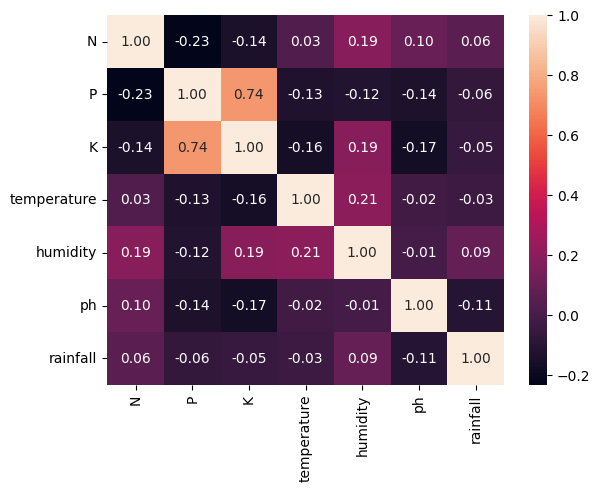

In [7]:
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt='.2f')

col----> N


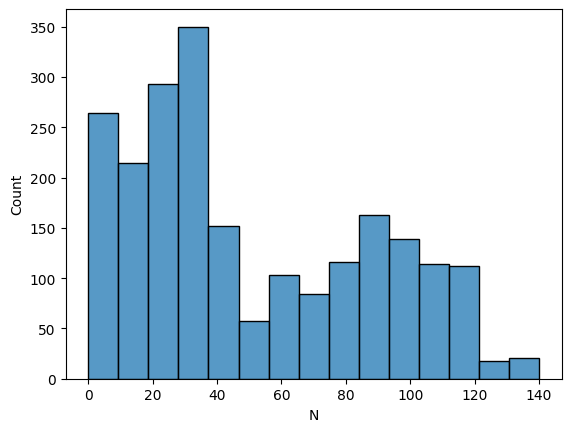

col----> P


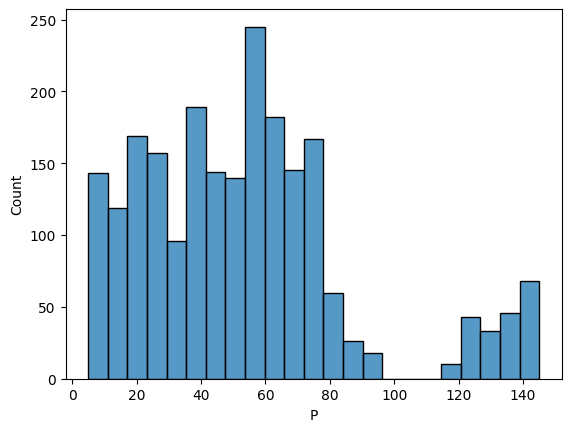

col----> K


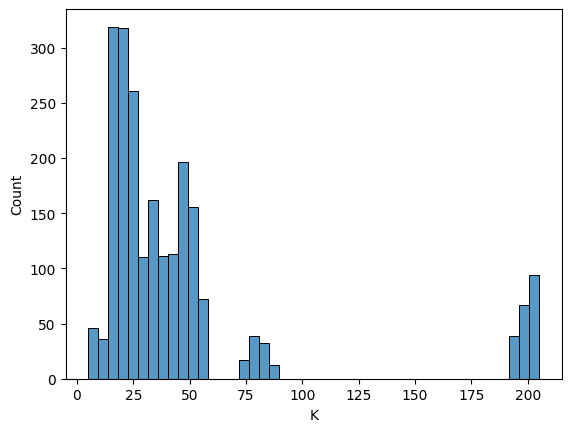

col----> temperature


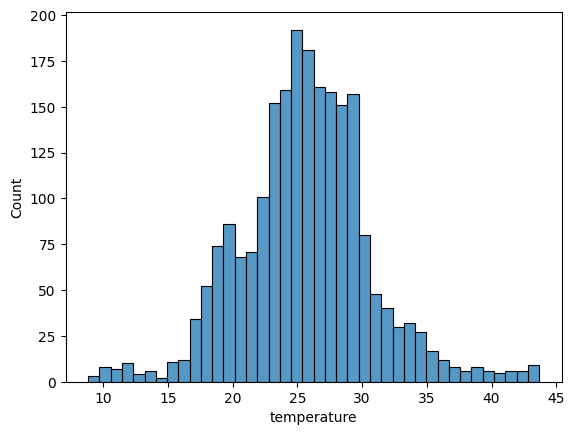

col----> humidity


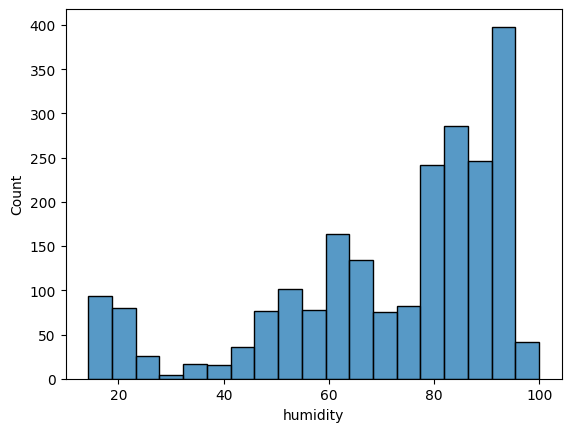

col----> ph


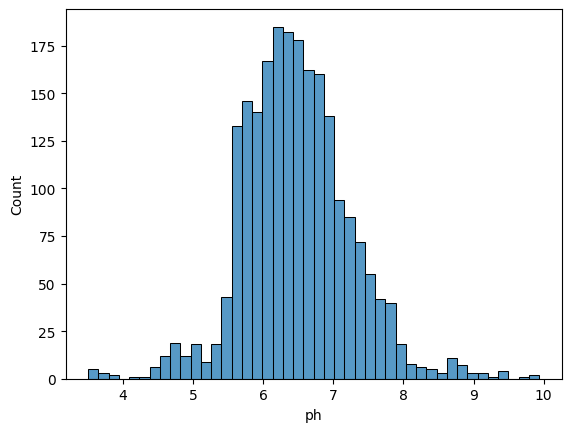

col----> rainfall


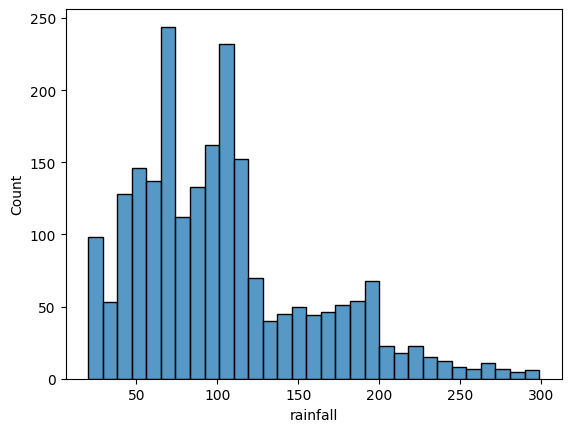

In [8]:
lst=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
for i in lst:
    print('col---->', i)
    sns.histplot(data=df, x=i)
    plt.show()

col----> N


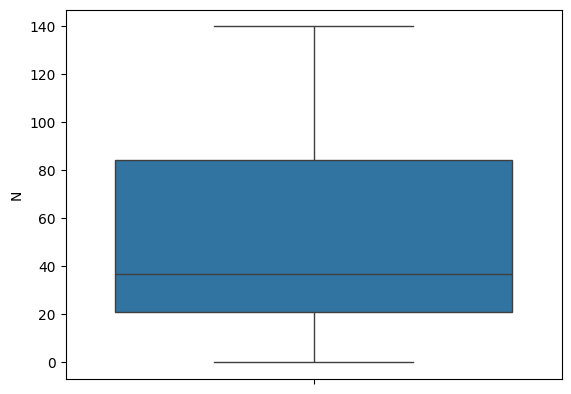

col----> P


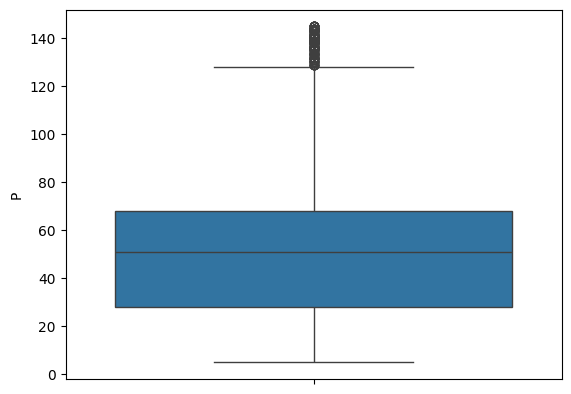

col----> K


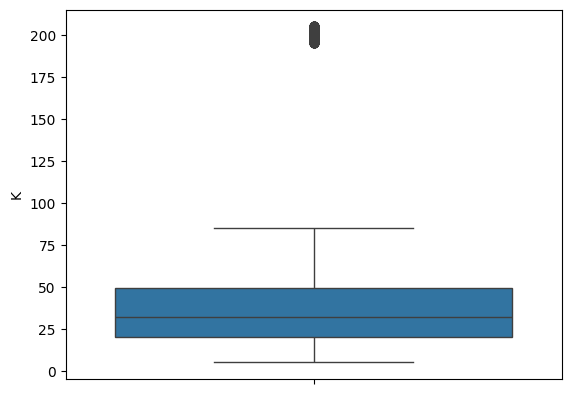

col----> temperature


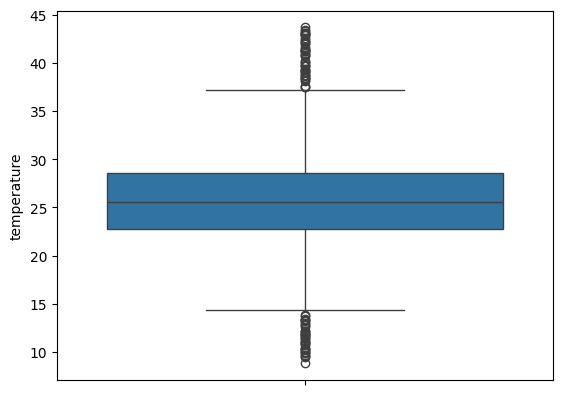

col----> humidity


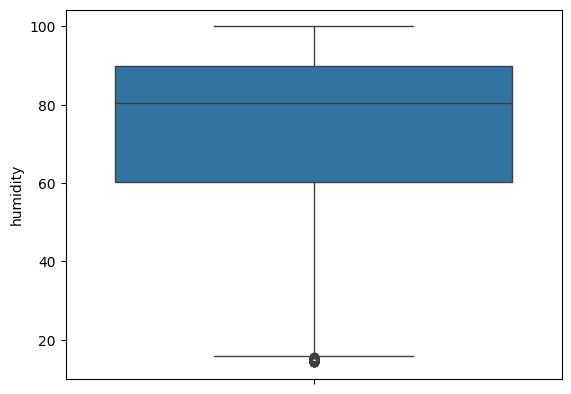

col----> ph


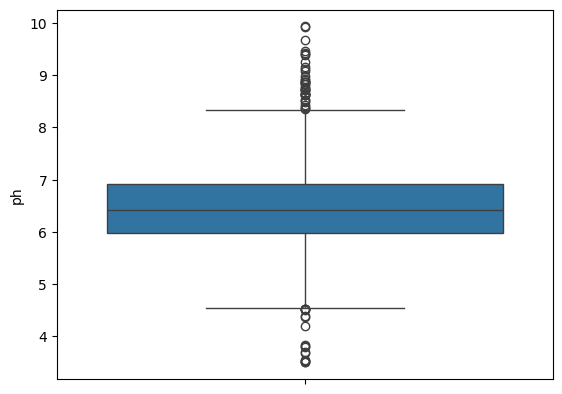

col----> rainfall


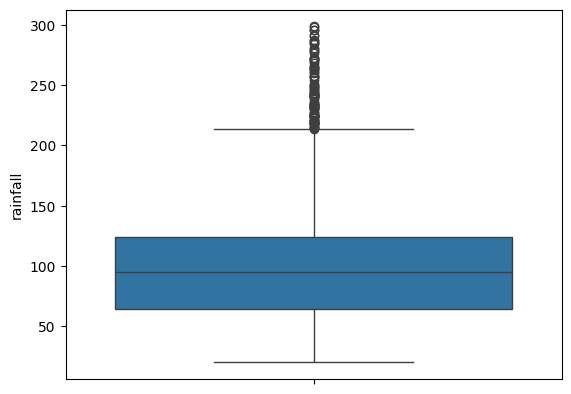

In [9]:
lst=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
for i in lst:
    print('col---->', i)
    sns.boxplot(data=df,y=i)
    plt.show()

In [10]:
lst=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
for i in lst:
    print('col---->', i)
    q1=df[i].quantile(0.25)
    q3=df[i].quantile(0.75)
    iqr=q3-q1
    lower=q1-1.5*iqr
    upper=q3+1.5*iqr
    outliers=df[(df[i]<=lower)|(df[i]>=upper)]
    print(f'outliers are \n',outliers[i])
    print(f'noumber of outliers are \n',len(outliers))
    print('*'*100)

col----> N
outliers are 
 Series([], Name: N, dtype: int64)
noumber of outliers are 
 0
****************************************************************************************************
col----> P
outliers are 
 1200    130
1201    144
1204    131
1206    140
1209    134
       ... 
1594    145
1596    132
1597    137
1598    144
1599    140
Name: P, Length: 144, dtype: int64
noumber of outliers are 
 144
****************************************************************************************************
col----> K
outliers are 
 1200    195
1201    204
1202    205
1203    196
1204    196
       ... 
1595    197
1596    198
1597    196
1598    196
1599    197
Name: K, Length: 200, dtype: int64
noumber of outliers are 
 200
****************************************************************************************************
col----> temperature
outliers are 
 1203    37.465668
1205    39.648519
1207    12.141907
1208    12.756796
1209    39.040720
          ...    
1786    40.004391
1

In [11]:
x=df.drop(columns='label')
y=df['label']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30,random_state=42)

In [12]:
# print(x_train.shape)-(1540, 7)
# print(x_test.shape)-(660, 7)

# KNN

In [13]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [14]:
knn=KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train_scaled,y_train)
y_pred_knn=knn.predict(x_test_scaled)

In [15]:
(y_test==y_pred_knn).sum()

np.int64(633)

In [16]:
(y_test!=y_pred_knn).sum()

np.int64(27)

In [17]:
# for actual,predicted in zip(y_test,y_pred_knn):
#   print(actual,'------',predicted)

In [18]:
acc_knn=accuracy_score(y_test,y_pred_knn)
acc_knn*100

95.9090909090909

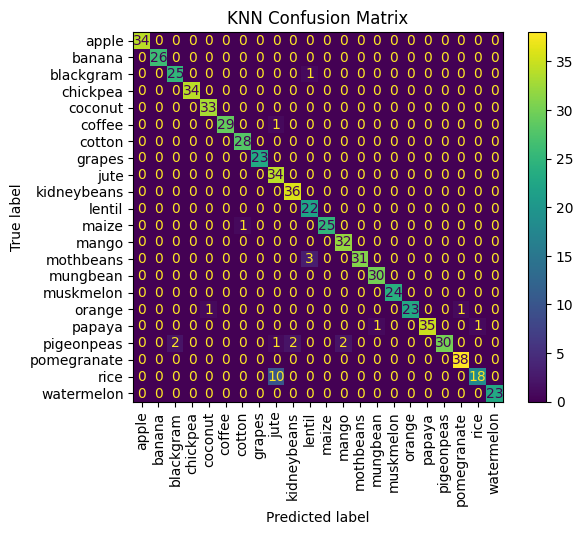

In [19]:
cm_knn=confusion_matrix(y_test,y_pred_knn)
cmd_knn=ConfusionMatrixDisplay(confusion_matrix=cm_knn,display_labels=knn.classes_)
cmd_knn.plot(xticks_rotation=90)
plt.title("KNN Confusion Matrix")
plt.show()

In [20]:
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        34
      banana       1.00      1.00      1.00        26
   blackgram       0.93      0.96      0.94        26
    chickpea       1.00      1.00      1.00        34
     coconut       0.97      1.00      0.99        33
      coffee       1.00      0.97      0.98        30
      cotton       0.97      1.00      0.98        28
      grapes       1.00      1.00      1.00        23
        jute       0.74      1.00      0.85        34
 kidneybeans       0.95      1.00      0.97        36
      lentil       0.85      1.00      0.92        22
       maize       1.00      0.96      0.98        26
       mango       0.94      1.00      0.97        32
   mothbeans       1.00      0.91      0.95        34
    mungbean       0.97      1.00      0.98        30
   muskmelon       1.00      1.00      1.00        24
      orange       1.00      0.92      0.96        25
      papaya       1.00    

# NAIVE BAYES

In [21]:
nb=GaussianNB()
nb.fit(x_train,y_train)
y_pred_nb=nb.predict(x_test)

In [22]:
(y_test==y_pred_nb).sum()

np.int64(656)

In [23]:
(y_test!=y_pred_nb).sum()

np.int64(4)

In [24]:
# for act, pred in zip(y_test, y_pred_nb):
#     print(act, '-----', pred)

In [25]:
acc_nb=accuracy_score(y_test,y_pred_nb)
acc_nb*100

99.39393939393939

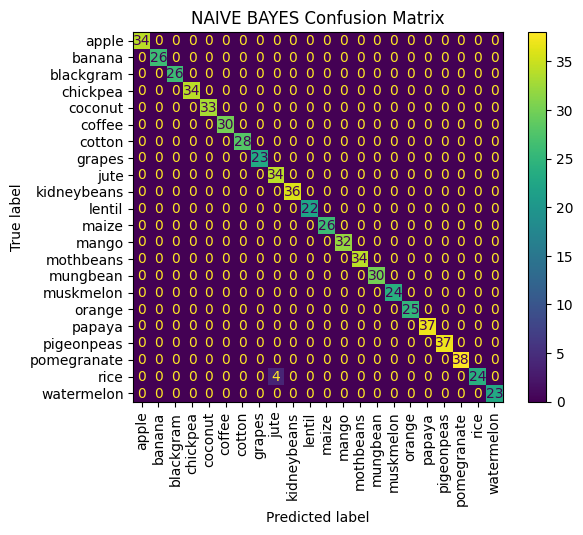

In [26]:
cm_nb=confusion_matrix(y_test,y_pred_nb)
cmd_nb=ConfusionMatrixDisplay(confusion_matrix=cm_nb,display_labels=nb.classes_)
cmd_nb.plot(xticks_rotation=90)
plt.title('NAIVE BAYES Confusion Matrix')
plt.show()

In [27]:
print(classification_report(y_test,y_pred_nb))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        34
      banana       1.00      1.00      1.00        26
   blackgram       1.00      1.00      1.00        26
    chickpea       1.00      1.00      1.00        34
     coconut       1.00      1.00      1.00        33
      coffee       1.00      1.00      1.00        30
      cotton       1.00      1.00      1.00        28
      grapes       1.00      1.00      1.00        23
        jute       0.89      1.00      0.94        34
 kidneybeans       1.00      1.00      1.00        36
      lentil       1.00      1.00      1.00        22
       maize       1.00      1.00      1.00        26
       mango       1.00      1.00      1.00        32
   mothbeans       1.00      1.00      1.00        34
    mungbean       1.00      1.00      1.00        30
   muskmelon       1.00      1.00      1.00        24
      orange       1.00      1.00      1.00        25
      papaya       1.00    

# COMPARING KNN AND NB


In [28]:
# MODEL COMPARISON
train_score_knn = knn.score(x_train_scaled, y_train)
test_score_knn = knn.score(x_test_scaled, y_test)

print("Training Accuracy of KNN:", train_score_knn * 100)
print("Testing Accuracy of KNN:", test_score_knn * 100)
print()
train_score_nb = nb.score(x_train, y_train)
test_score_nb = nb.score(x_test, y_test)

print("Training Accuracy of NAIVE BAYES:", train_score_nb * 100)
print("Testing Accuracy of NAIVE BAYES", test_score_nb * 100)


Training Accuracy of KNN: 98.24675324675324
Testing Accuracy of KNN: 95.9090909090909

Training Accuracy of NAIVE BAYES: 99.54545454545455
Testing Accuracy of NAIVE BAYES 99.39393939393939


In [34]:
comparison = pd.DataFrame({
    'Evaluation Metric': ['Training Accuracy', 'Testing Accuracy',
                          'Precision', 'Recall', 'F1-score'],

    'KNN': [
        knn.score(x_train_scaled, y_train) * 100,
        knn.score(x_test_scaled, y_test) * 100,
        precision_score(y_test, y_pred_knn, average='weighted') * 100,
        recall_score(y_test, y_pred_knn, average='weighted') * 100,
        f1_score(y_test, y_pred_knn, average='weighted') * 100
    ],

    'Naive Bayes': [
        nb.score(x_train, y_train) * 100,
        nb.score(x_test, y_test) * 100,
        precision_score(y_test, y_pred_nb, average='weighted') * 100,
        recall_score(y_test, y_pred_nb, average='weighted') * 100,
        f1_score(y_test, y_pred_nb, average='weighted') * 100
    ]
})

print(comparison)

   Evaluation Metric        KNN  Naive Bayes
0  Training Accuracy  98.246753    99.545455
1   Testing Accuracy  95.909091    99.393939
2          Precision  96.468320    99.457735
3             Recall  95.909091    99.393939
4           F1-score  95.849607    99.387464


SAMPLE CROP PREDICTION

In [31]:
print(x.columns)

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'], dtype='object')


In [32]:
sample = pd.DataFrame({
    'N': [90],
    'P': [42],
    'K': [43],
    'temperature': [20.8],
    'humidity': [82.0],
    'ph': [6.5],
    'rainfall': [202.9]
})
sample_scaled=scaler.transform(sample)
prediction_knn=knn.predict(sample_scaled)
prediction_nb=nb.predict(sample)
print("KNN predcted crop is ",prediction_knn[0])
print("NAIVE BAYES predcted crop is ",prediction_nb[0])

KNN predcted crop is  rice
NAIVE BAYES predcted crop is  rice


## FINAL CONCLUSION

In this project, two machine learning algorithms, K-Nearest Neighbors (KNN) and Gaussian Naive Bayes, were implemented for crop prediction using soil and weather parameters.

Both models were evaluated using training accuracy, testing accuracy, precision, recall, F1-score and confusion matrices.

KNN achieved a testing accuracy of 95.91%, while Gaussian Naive Bayes achieved 99.39%.

Based on the evaluation results, Gaussian Naive Bayes performed better than KNN on this dataset.

The project demonstrates how machine learning can help predict suitable crops based on soil nutrients and environmental conditions.